# 品质理论：转移矩阵、纯回收机与组装-回收环

官方文档：https://wiki.factorio.com/Quality/zh

**一句话结论**：原料用产能机堆量，最终一步品质组装按 wiki 配比全档统一，不用搞多级品质前处理链。

## 1 基础转移矩阵

### 1.1 两个表达式

输出 = 输入 × 转移矩阵：

$$g = f\,M$$

转移矩阵 = 出入比例 × 品质矩阵（$Q$ 取 **Quality** 的首字母）：

$$M = \mathrm{diag}(r)\,Q(q)$$

### 1.1.1 记号与约定

- **品质等级**：叙述一律用 $1$–$5$ 的等级编号——$1$=普通、$2$=优秀、$3$=稀有、$4$=史诗、$5$=传奇（口语“$k$ 星”即等级 $k$）；代码实现里再用 $0$-index（$0..4$）与之对应。
- $i \in \{1,2,3,4,5\}$：品质等级指标，记传奇档 $L := 5$。
- $q$：单次制作的品质概率（最终 roll 概率），由设备插槽上的品质插件加成叠加而来：若有 $4$ 个插槽、每个品质插件提供 $2.5\%$，则 $q = 4\times 2.5\% = 10\%$，即 $q=\text{插槽数}\times\text{单插件倍率}$（同规格插件时；不同规格取各自倍率之和）。
- $r$：**出入比例**——产出组数 / 投入组数（已含全部产能来源，按“一组”计，与配方件数无关，例如 $1$ 铜块 $\to$ $2$ 铜线的配方 $r$ 依然是 $1$）。$r$ 的来源枚举如下：
  1. **设备产能**：部分设备自带产能，如铸造厂、电磁工厂；
  2. **产能插件**：插在设备上的产能插件加成；
  以上两项合并计入组装侧：$r = 1+P$，其中 $P$ 为“设备自带 + 插件”的总产能加成（如 $50\%$ 产能即 $P=0.5$）；
  3. **回收机**：固定保留 $\tfrac14$（湮灭 $\tfrac34$），即 $r = \tfrac14$（游戏定值，不参数化）。
- $e_i$：第 $i$ 个分量为 $1$ 的列向量（$5\times 1$）；$e_L$ 即传奇收集指示向量；$\mathbf 1$ 为全 $1$ 列向量。
- **流体**：不受品质机制约束——**不是**令 $q=0$，而是在本理论中**没有任何表现**（没有任何表达式与流体相关）。
- 即使有一天要考虑流体，这里也不会变化——$1$ 份原材料 $\to$ $1$ 份产品仍然是 $M = \mathrm{diag}(1)$。此处仅作游戏机制的提示。

### 1.1.2 状态向量与转移矩阵

- $f = (f_1,f_2,f_3,f_4,f_5)$：$f_k$ 为等级 $k$ 的物品量。
- 单位是“**组**”——产出 $1$ 件产品所需的若干原料算 $1$ 组（如 $1$ 铜块 $\to$ $2$ 铜线时，$2$ 根铜线为 $1$ 组），因此量与配方件数无关。
- $M$ 的第 $i$ 行第 $j$ 列：输入品质 $i$ 时产出品质 $j$ 的**期望倍数**（$=$ 概率 $\times$ 出入比例）。
- $g = fM$ 即作用一次后各等级的量；多级设备串联即矩阵连乘。
- 循环系统展开为无限长直线链。

### 1.1.3 特例：普通生产、组装机与回收机的基础矩阵

在 $g = fM$ 中取 $M = \mathrm{diag}(r)\,Q(q)$，按 $r$ 的来源特例化：

- **普通生产**（无品质、无产能）：$M = I = \mathrm{diag}(1)$，品质与数量都不变。
- **组装机**：$M = \mathrm{diag}(1+P)\,Q(q)$，$P$ 为设备自带产能（铸造厂、电磁工厂等）与产能插件的合计。
- **回收机**：$M = \mathrm{diag}(\tfrac14)\,Q(q)$，固定湮灭 $\tfrac34$（游戏定值，不参数化）。

三者都可直接左乘状态：$g = fM$。

可作为练习：取具体 $f$ 与 $q$ 手算一遍 $g$，并检验 $Q(q)$ 行和为 $1$（品质滚动本身不改变件数，变化只来自 $r$）。

若各等级配置不同（如低等级挂品质插件、高等级挂产能插件），可逐行取 $(q_i, r_i)$；细节留待模拟代码建模。

### 1.2 品质矩阵 $Q(q)$

$$
Q(q) =
\begin{pmatrix}
1-q & 9q\cdot10^{-1} & 9q\cdot10^{-2} & 9q\cdot10^{-3} & q\cdot10^{-3}\\
0 & 1-q & 9q\cdot10^{-1} & 9q\cdot10^{-2} & q\cdot10^{-2}\\
0 & 0 & 1-q & 9q\cdot10^{-1} & q\cdot10^{-1}\\
0 & 0 & 0 & 1-q & q\\
0 & 0 & 0 & 0 & 1
\end{pmatrix}.
$$

### 1.2.1 滚动机制、分段通式与校验

**滚动机制**（官方）：

- 先以概率 $q$ 首次判定；成功则升一档；
- 再以固定 $10\%$ 的概率继续判定，直到失败；传奇为吸收态；
- **不可能跳档**（连续升级是逐档累乘 $1/10$ 的几何因子，而非品质加成的幂次）。

由此得到分段通式：

$$
Q(q)_{ij} =
\begin{cases}
0, & j < i,\\[4pt]
1-q, & j = i,\\[4pt]
\dfrac{9q}{10}\cdot 10^{-(j-i-1)}, & i < j < L,\\[6pt]
q\cdot 10^{-(L-i-1)}, & j = L > i.
\end{cases}
$$

以等级 $1$（普通）行为例，与 wiki 表格逐项一致：升 1 档 $\tfrac{9}{10}q$，升 2 档 $\tfrac{9}{100}q$，升 3 档 $\tfrac{9}{1000}q$，直升传奇 $\tfrac{1}{1000}q$。

**注意**：$Q(q)$ 是一般转移矩阵 $M$ 的特例——只有品质滚动、出入比例 $r\equiv 1$；加上产能或湮灭后即 $M = \mathrm{diag}(r)\,Q(q)$。

### 1.3 范围：不考虑速度与节能插件

模型只考虑**品质插件**与**产能插件**（分别进入 $q$ 与 $r$）。

- **速度插件**：不考虑。它只会降低 $q$（挤占品质插件的槽位），对 $r$ 没有影响；吞吐不足完全可以用**多铺设备**补足，速度只是工程侧变量。
- **节能插件**：不考虑。电能消耗不需要优化，只要**供电充足**即可，模型不引入能耗约束。

## 2 纯回收机循环

模型背景：把物品反复送入回收机，目标是收集传奇产物（例如“铁板 $\to$ 传奇铁板”的自循环）。

回收机湮灭 $3/4$ 的物品，未湮灭的以品质分布返回，传奇则被移出系统。

**TL;DR** 本章闭式：回收循环矩阵 $M = R\,(I - SR)^{-1}\,C$，传奇产出 $\mathbf y = fM$。

### 2.1 设定与湮灭率

- 回收机固定保留 $\tfrac14$（湮灭 $\tfrac34$）：游戏定值、无需参数化；组归一化下与配方件数无关。
- 回收机的品质概率 $q$ 由品质插件决定。
- 进料为行向量 $f$（$1\times 5$，通常 $f_L = 0$；若 $f_L>0$，传奇进料会因下行清零而直接离开系统，即被收集）。

### 2.2 收集矩阵与回收矩阵

系统把**收集**（传奇产品移出系统）与**继续回收**（非传奇部分再过机）分开处理。定义**收集矩阵**（Collect）

$$
C := \mathrm{diag}(0,0,0,0,1),
$$

它只保留传奇（5 星）分量。

$g = fM$ 是产出向量，则 $gC = fMC$ 就是产出中的传奇产品向量；剩余部分用**通过掩码**表示

$$
S := I - C = \mathrm{diag}(1,1,1,1,0).
$$

**回收矩阵**（$R$ 取 **recycle** 的首字母；不预先清行）为

$$
R := \tfrac14\, Q(q).
$$

一次过机的分解：产出为 $fR$，其中被收集走的是 $fRC$，继续留在循环里的是 $fRS$。

（行向量约定下掩码体现为右乘以筛选分量；列向量约定下对应形式为左乘。）

### 2.3 循环展开、闭式与数值截断

对画图与模拟，循环用编译原理的**循环展开**处理：把回收机的逐次通过展开成有限长的链即可，

$$
fR \;\to\; \underbrace{fRC}_{\text{收集}} \;+\; \underbrace{fRS}_{\text{继续}},
\qquad
fRSR \;\to\; \underbrace{fRSRC}_{\text{收集}} \;+\; \underbrace{fRSRS}_{\text{继续}},\quad \cdots
$$

代数式则直接求和。总收集（各等级的传奇产出向量 $\mathbf y$）为

$$
\mathbf y \;=\; fRC + fRSRC + fRSRSRC + \cdots \;=\; fR\bigl(I + SR + (SR)^2 + \cdots\bigr)C
\;=\; fR\,(I - SR)^{-1}\,C,
$$

- 标量产出 $y = \mathbf y\,\mathbf 1 = fR(I-SR)^{-1}C\,\mathbf 1$。
- 非传奇存量为 $s_k = f(SR)^k$（$(SR)^k$ 的传奇分量恒为 $0$）。

因为每过一次机都有 $\tfrac34$ 被湮灭，$(SR)^k$ 的行和以 $(\tfrac14)^k$ 几何衰减：$\|SR\|_\infty \le \|R\|_\infty \le \tfrac14 < 1$，级数收敛，链“不那么长”。

- 数值模拟可以很快截断（逐段累加直到余项小于容差）。
- 矩阵等比数列求和 $(I-SR)^{-1}$ 与截断等价，**实际实现建议用数值截断**。

## 3 组装机 + 回收机循环

模型背景：组装机把材料制成产品，非传奇产品送回收机拆回材料，材料再回组装机。

只把**传奇产品**移出系统（传奇材料继续作为组装机输入，最终仍以传奇产品形式离开）。

**TL;DR** 本章闭式：组装-回收循环矩阵 $M = A\,(I - SRA)^{-1}\,C$，传奇产出 $\mathbf y = fM$。

### 3.1 组装矩阵 $A = \mathrm{diag}(1+P)\,Q(q)$

$A$ 取 **Assembling**（组装）的首字母。

$P$ 为产能加成（设备自带产能 + 产能插件），$Q(q)$ 为品质矩阵：

$$
A = \mathrm{diag}(1+P)\,Q(q).
$$

即组装机特例的一般形式。

### 3.2 单轮

就一轮（不迭代、不更新进料）：进料 $f$ 组装后，产出 $fA$ 分两路——

$$
fA \;\to\; \underbrace{fAC}_{\text{收集}} \;+\; \underbrace{fAS}_{\text{非传奇}}
\;\to\; \underbrace{fASR}_{\text{回收产出}} .
$$

注意：$fASR$ 不被直接收集——它是材料，收集只作用于产品。第二轮把同样的因子再乘一遍：材料 $fASR$ 组装为 $fASRA$，收集 $fASRAC$，非传奇 $fASRAS$ 回收 $fASRASR$，即每轮都是同样的 $AC$（收集）与 $ASR$（组装-掩码-回收）。

注（与 wiki 的关联）：wiki 用 10 维轮转矩阵 $\begin{pmatrix}0&A\\SR&0\end{pmatrix}$ 记账（前 5 材料、后 5 产品，列向量约定下需转置），把材料、产品拼成一个状态；

其 $T^2$ 的左上角即 $ASR$，与这里的 5 维一轮链等价。

### 3.3 闭式与级数

把每轮的收集直接加起来（逐轮展开即得）：

$$
y \;=\; fAC + fASRAC + fASRASRAC + \cdots
\;=\; fA\bigl(I + SRA + (SRA)^2 + \cdots\bigr)C
\;=\; fA\,(I - SRA)^{-1}\,C .
$$

- $y$ 为各品质等级的传奇产出向量，传奇总量取其 $L$ 分量（或右乘 $\mathbf 1$）。
- 同理：每轮都湮灭掉一大块，级数快速收敛，工程实现直接数值截断（逐轮累加直到余项小于容差）即可。
- 收敛要求 $(1+P)\cdot\tfrac14 < 1$，即总产能倍率 $1+P < 400\%$（等价于产能加成 $P < 300\%$）——逼近临界时收敛变慢，超过后系统发散。（wiki “趋近 $400\%$”指的就是 $1+P$。）

## 4 代码实现与常见计算

用 numpy 实现前三章。代码里等级用 $0$-index（$0=$ 普通，$\dots$，$4=$ 传奇），与叙述的 $1$–$5$ 等级相差 $1$。

### 4.1 基础转移矩阵

先定义常量：品质/产能插件 3 在各品质下的单插件加成、组装类设备的基础产能与插槽数。然后是品质矩阵 $Q(q)$、转移矩阵 $M = \mathrm{diag}(r)\,Q(q)$、通用组装矩阵与各设备工厂函数。

设备工厂返回的组装矩阵在 5->5 系数上做了调整：回收机会把一部分史诗升级为传奇料，传奇料再进组装时品质插件完全无效（已是最高等级），应按**纯产能**计算——$A_{5,5} = 1 + P_{\mathrm{leg}}$，$P_{\mathrm{leg}}$ = 设备基础产能 + 全部插槽放产能插件（按调用给定的产能插件档位 `p_t` 算；设备禁产能插件/非中间产物时传 `p_t=0`，此时 $P_{\mathrm{leg}}$ 只剩基础产能）。这与 wiki 最优插件表一致（5 槽 50% 基础产能做传奇：4 产能 + 1 品质）。$Q$、$R$ 本身不变。

In [1]:
import numpy as np

# 品质插件 3：单插件品质加成，索引 = 品质档位（0=无, 1=普通 .. 5=传奇），叠加进 q
QUALITY_MOD3 = np.array([0.0, 0.025, 0.032, 0.04, 0.047, 0.062])

# 产能插件 3：单插件产能加成，索引 = 品质档位（0=无, 1=普通 .. 5=传奇），叠加进 P
PRODUCTIVITY_MOD3 = np.array([0.0, 0.10, 0.13, 0.16, 0.19, 0.25])

# 组装类设备：基础产能加成、插槽数（品质系统为通关后内容，默认只用最高级）
MACHINES = {
    "组装机3": {"base_productivity": 0.0, "slots": 4},
    "电磁工厂": {"base_productivity": 0.50, "slots": 5},
    "铸造厂": {"base_productivity": 0.50, "slots": 4},
    "电炉": {"base_productivity": 0.0, "slots": 2},
    "化工厂": {"base_productivity": 0.0, "slots": 3},
    "低温工厂": {"base_productivity": 0.0, "slots": 8},
}

In [2]:
def Q(q):
    """品质矩阵（0-index：4=传奇）。"""
    Qm = np.zeros((5, 5))
    for i in range(5):
        Qm[i, i] = 1 - q
        for j in range(i + 1, 5):
            if j < 4:
                Qm[i, j] = 0.9 * q * 10 ** (-(j - i - 1))
            else:
                Qm[i, j] = q * 10 ** (-(4 - i - 1))
    Qm[4, 4] = 1.0
    return Qm


def diag(r):
    return np.diag(np.asarray(r, dtype=float))


np.set_printoptions(precision=4, suppress=True)

print(Q(0.08))

[[0.92   0.072  0.0072 0.0007 0.0001]
 [0.     0.92   0.072  0.0072 0.0008]
 [0.     0.     0.92   0.072  0.008 ]
 [0.     0.     0.     0.92   0.08  ]
 [0.     0.     0.     0.     1.    ]]


In [3]:
f = np.array([1.0, 0, 0, 0, 0])  # 进料：1 组普通品质


def assembler_matrix(extra_productivity, total_q):
    """[弃用] 通用组装矩阵：A = diag(1+P) Q(q)。

    弃用原因：缺 5->5 调整（传奇输入时品质插件无效、只应保留产能效果）；
    请用 make_assembler，其 build 已内置该调整。
    """
    return diag([1 + extra_productivity] * 5) @ Q(total_q)


def recycler(q_t):
    """回收机矩阵：R = (1/4) Q(q)。插槽固定 4 个品质插件。"""
    # q_t: 品质档位（1=普通 .. 5=传奇），q = 4 x 该档位单插件加成
    q = 4 * QUALITY_MOD3[q_t]
    return 0.25 * Q(q)


def make_assembler(name):
    """设备工厂：按插件配置返回该设备的组装矩阵（含 5->5 调整，见 4.1 说明）。"""
    spec = MACHINES[name]  # 该设备的基础产能与插槽数

    def build(q_n, q_t, p_n, p_t):
        # q_n, q_t: 品质插件个数、品质档位（1=普通 .. 5=传奇，0=无）
        # p_n, p_t: 产能插件个数、产能档位（设备禁产能插件/非中间产物时传 p_t=0）
        if q_n + p_n > spec["slots"]:
            raise ValueError(f"{name}: 插件总数 {q_n + p_n} 超过插槽数 {spec['slots']}")
        q = q_n * QUALITY_MOD3[q_t]  # 品质插件叠加出最终 q
        P = spec["base_productivity"] + p_n * PRODUCTIVITY_MOD3[p_t]  # 基础 + 插件产能
        A = diag([1 + P] * 5) @ Q(q)
        # 5->5：传奇输入时品质插件无效，全插槽按 p_t 档产能算
        A[4, 4] = 1 + spec["base_productivity"] + spec["slots"] * PRODUCTIVITY_MOD3[p_t]
        return A

    return build


assembler3 = make_assembler("组装机3")
electromagnetic_plant = make_assembler("电磁工厂")
foundry = make_assembler("铸造厂")
electric_furnace = make_assembler("电炉")
chemical_plant = make_assembler("化工厂")
cryogenic_plant = make_assembler("低温工厂")

# 进料 f 与普通生产：M = I
print("进料 f =", f)
print("普通生产 g = fM:", f @ np.eye(5))

# 电磁工厂：5 个史诗品质插件 3（基础产能 50%）
A = electromagnetic_plant(q_n=5, q_t=4, p_n=0, p_t=0)
print("电磁工厂（5x史诗品质 q=23.5%, P=50%）:")
print(A)

# 组装机3：4 个传奇品质插件 3
A = assembler3(q_n=4, q_t=5, p_n=0, p_t=0)
print("组装机3（4x传奇品质 q=24.8%, P=0%）:")
print(A)

# 回收机：4 个普通品质插件 3
R = recycler(q_t=1)
print("回收机（4x普通品质 q=10%, 保留 1/4）:")
print(R)

进料 f = [1. 0. 0. 0. 0.]
普通生产 g = fM: [1. 0. 0. 0. 0.]
电磁工厂（5x史诗品质 q=23.5%, P=50%）:
[[1.1475 0.3172 0.0317 0.0032 0.0004]
 [0.     1.1475 0.3172 0.0317 0.0035]
 [0.     0.     1.1475 0.3172 0.0353]
 [0.     0.     0.     1.1475 0.3525]
 [0.     0.     0.     0.     1.5   ]]
组装机3（4x传奇品质 q=24.8%, P=0%）:
[[0.752  0.2232 0.0223 0.0022 0.0002]
 [0.     0.752  0.2232 0.0223 0.0025]
 [0.     0.     0.752  0.2232 0.0248]
 [0.     0.     0.     0.752  0.248 ]
 [0.     0.     0.     0.     1.    ]]
回收机（4x普通品质 q=10%, 保留 1/4）:
[[0.225  0.0225 0.0023 0.0002 0.    ]
 [0.     0.225  0.0225 0.0023 0.0003]
 [0.     0.     0.225  0.0225 0.0025]
 [0.     0.     0.     0.225  0.025 ]
 [0.     0.     0.     0.     0.25  ]]


### 4.2 纯回收机循环

收集矩阵 $C$、通过掩码 $S = I - C$、回收矩阵 $R = \tfrac14 Q(q)$（`recycler(q_t)`：固定 4 个品质插件，$q = 4 \times \mathrm{QUALITY\_MOD3}[q_t]$）。两个锚点：循环展开截断、闭式对照。

In [4]:
C = np.zeros((5, 5))
C[4, 4] = 1.0
S = np.eye(5) - C
L = np.array([0.0, 0, 0, 0, 1])  # 传奇取值向量：对行向量 x，x @ L 即其传奇分量（= C 的第 5 行）

print("收集矩阵 C:")
print(C)
print("通过掩码 S = I - C:")
print(S)


def recycler_collect(q_t, feed, eps=1e-12, max_passes=200):
    """循环展开若干过机，只收集传奇产品，误差小于 eps 时截断。"""
    R = recycler(q_t=q_t)
    q = 4 * QUALITY_MOD3[q_t]  # 该档位的最终品质概率
    y = np.zeros(5)
    s = feed.copy()
    for k in range(max_passes):
        out = s @ R
        y = y + out @ C
        s = out @ S
        if np.abs(s).sum() < eps:
            return y, k + 1, q
    return y, max_passes, q


# 纯铁片循环：进料 1 组普通铁片，对比各星级品质插件
for q_t in range(1, 6):
    y, passes, q = recycler_collect(q_t, f)
    R = recycler(q_t=q_t)
    y_closed = f @ R @ np.linalg.inv(np.eye(5) - S @ R) @ C
    print(
        f"{q_t} 星（q = 4 x {QUALITY_MOD3[q_t]:.1%} = {q:.1%}）:"
        f" 传奇收集 = {(y @ L) * 100:.6g}% | 进料比 = {1 / (y @ L):.6g} : 1"
        f" | 与闭式之差 = {abs((y @ L) - (y_closed @ L)):.1e}"
    )

收集矩阵 C:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]]
通过掩码 S = I - C:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0.]]
1 星（q = 4 x 2.5% = 10.0%）: 传奇收集 = 0.00693% | 进料比 = 14430 : 1 | 与闭式之差 = 6.6e-15
2 星（q = 4 x 3.2% = 12.8%）: 传奇收集 = 0.0104827% | 进料比 = 9539.5 : 1 | 与闭式之差 = 9.3e-15
3 星（q = 4 x 4.0% = 16.0%）: 传奇收集 = 0.0156187% | 进料比 = 6402.58 : 1 | 与闭式之差 = 1.1e-14
4 星（q = 4 x 4.7% = 18.8%）: 传奇收集 = 0.0211516% | 进料比 = 4727.77 : 1 | 与闭式之差 = 1.1e-14
5 星（q = 4 x 6.2% = 24.8%）: 传奇收集 = 0.0366716% | 进料比 = 2726.91 : 1 | 与闭式之差 = 3.9e-14


### 4.3 组装机 + 回收机循环

单轮链 $fA \to fAC + fAS \to fASR$，稳态 $m = f(I-ASR)^{-1}$、$p = mA$。锚点：$q = 25\%$、$P = 50\%$ 的 wiki 示例。然后封装两个函数：可插产能设备求最优配比（枚举品质/产能插件分配），不可插产能设备全塞品质插件（唯一输出）。

In [5]:
q, P = 0.25, 0.50
A = diag([1 + P] * 5) @ Q(q)  # 展开 assembler_matrix（已弃用）
# wiki 示例中回收机 q 与组装机相同（25% 非 4 插件档位组合），故直接构造 R
R = 0.25 * Q(q)

# 单轮
print("fA   =", f @ A, "组装产出")
print("fAC  =", f @ A @ C, "收集")
print("fAS  =", f @ A @ S, "非传奇")
print("fASR =", f @ A @ S @ R, "回收产出")

# 稳态
K = A @ S @ R
m = f @ np.linalg.inv(np.eye(5) - K)
p = m @ A
print("m =", m)
print("p =", p)
print(f"传奇产品占比 = {(p @ L):.5%}")

fA   = [1.125  0.3375 0.0338 0.0034 0.0004] 组装产出
fAC  = [0.     0.     0.     0.     0.0004] 收集
fAS  = [1.125  0.3375 0.0338 0.0034 0.    ] 非传奇
fASR = [0.2109 0.1266 0.0316 0.0051 0.0007] 回收产出
m = [1.2673 0.2033 0.0834 0.0297 0.0063]
p = [1.4257 0.6564 0.2052 0.0727 0.025 ]
传奇产品占比 = 2.49747%


In [6]:
def legendary_yield(A, R, head=None, eps=1e-12, max_rounds=200):
    """逐轮展开 y = f·head·A(I-SRA)^{-1}C，返回传奇产出与闭式之差（head 默认恒等，即无前置）。"""
    head = np.eye(5) if head is None else head
    series, y_sum = f @ head @ A, np.zeros(5)  # 第一轮组装产出
    for _ in range(max_rounds):
        y_sum = y_sum + series @ C  # 收集 f·head·A(SRA)^k C
        series = series @ S @ R @ A  # 下一轮：非传奇 -> 回收 -> 组装
        if np.abs(series).sum() < eps:
            break
    y_leg = (y_sum @ L)
    y_closed = (f @ head @ A @ np.linalg.inv(np.eye(5) - S @ R @ A) @ L)
    return y_leg, abs(y_leg - y_closed)


def quality_only(name, q_t):
    """不可插产能设备：全部插槽放 q_t 星品质插件，唯一配比。"""
    spec = MACHINES[name]
    slots = spec["slots"]
    build = make_assembler(name)
    A = build(q_n=slots, q_t=q_t, p_n=0, p_t=0)  # p_n = 0：无产能插件
    R = recycler(q_t=q_t)
    y_leg, diff = legendary_yield(A, R)
    print(
        f"{name}（全 {slots} 个 {q_t} 星品质）: q = {slots * QUALITY_MOD3[q_t]:.1%},"
        f" P = {spec['base_productivity']:.0%} | 传奇产出 = {y_leg * 100:.6g}%"
        f" | 进料比 = {1 / y_leg:.6g} : 1 | 与闭式之差 = {diff:.1e}"
    )
    return y_leg


def best_split(name, q_t, p_t):
    """可插产能设备的最优配比：品质插件数 + 产能插件数 = 插槽数，枚举并打印每种配比。"""
    spec = MACHINES[name]
    slots = spec["slots"]
    build = make_assembler(name)
    print(f"{name}（{q_t} 星品质 + {p_t} 星产能，{slots} 槽）:")
    best = (-1.0, None)
    for p_n in range(slots + 1):
        q_n = slots - p_n
        A = build(q_n=q_n, q_t=q_t, p_n=p_n, p_t=p_t)
        R = recycler(q_t=q_t)
        y_leg, diff = legendary_yield(A, R)
        P = spec["base_productivity"] + p_n * PRODUCTIVITY_MOD3[p_t]
        print(
            f"  产能x{p_n} 品质x{q_n}: q = {q_n * QUALITY_MOD3[q_t]:.1%}, P = {P:.0%}"
            f" | 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1"
            f" | 与闭式之差 = {diff:.1e}"
        )
        if y_leg > best[0]:
            best = (y_leg, (p_n, q_n))
    y_leg, (p_n, q_n) = best
    print(f"  最优: 产能x{p_n} 品质x{q_n} -> 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1")
    return best


# 电磁工厂做 CPU：大循环 = 插件品质，小循环 = 配比
print("进料 f =", f)
for q_t in range(1, 6):
    best_split("电磁工厂", q_t=q_t, p_t=q_t)

# 不可插产能设备：电炉（熔炉类禁止产能插件）
print()
for q_t in range(1, 6):
    quality_only("电炉", q_t=q_t)

# 电磁工厂做建筑：配方禁止产能插件，只能全品质
print()
for q_t in range(1, 6):
    quality_only("电磁工厂", q_t=q_t)

进料 f = [1. 0. 0. 0. 0.]
电磁工厂（1 星品质 + 1 星产能，5 槽）:
  产能x0 品质x5: q = 12.5%, P = 50% | 传奇产出 = 0.452485% | 进料比 = 221.002 : 1 | 与闭式之差 = 1.3e-13
  产能x1 品质x4: q = 10.0%, P = 60% | 传奇产出 = 0.416205% | 进料比 = 240.266 : 1 | 与闭式之差 = 1.3e-13
  产能x2 品质x3: q = 7.5%, P = 70% | 传奇产出 = 0.361223% | 进料比 = 276.837 : 1 | 与闭式之差 = 1.6e-13
  产能x3 品质x2: q = 5.0%, P = 80% | 传奇产出 = 0.288806% | 进料比 = 346.254 : 1 | 与闭式之差 = 9.6e-14
  产能x4 品质x1: q = 2.5%, P = 90% | 传奇产出 = 0.202534% | 进料比 = 493.744 : 1 | 与闭式之差 = 7.3e-14
  产能x5 品质x0: q = 0.0%, P = 100% | 传奇产出 = 0.109282% | 进料比 = 915.063 : 1 | 与闭式之差 = 6.6e-14
  最优: 产能x0 品质x5 -> 传奇产出 = 0.452485% | 进料比 = 221.002 : 1
电磁工厂（2 星品质 + 2 星产能，5 槽）:
  产能x0 品质x5: q = 16.0%, P = 50% | 传奇产出 = 0.828787% | 进料比 = 120.658 : 1 | 与闭式之差 = 1.7e-13
  产能x1 品质x4: q = 12.8%, P = 63% | 传奇产出 = 0.814702% | 进料比 = 122.744 : 1 | 与闭式之差 = 1.1e-13
  产能x2 品质x3: q = 9.6%, P = 76% | 传奇产出 = 0.754719% | 进料比 = 132.5 : 1 | 与闭式之差 = 1.0e-13
  产能x3 品质x2: q = 6.4%, P = 89% | 传奇产出 = 0.644372% | 进料比 = 155.19 : 1 | 与闭式之

### 4.4 M 算子（闭式封装）

4.1~4.3 用逐轮展开实现并与闭式对比，还不是直接用闭式。这里封装第 3 部分的闭式算子 $M = A\,(I - SRA)^{-1}\,C$：接受组装机名与插件个数/等级（同 4.1 设备工厂 `build` 的参数），返回 M；传奇产出 $\mathbf y = fM$（有前置时 $\mathbf y = f\cdot\mathrm{head}\cdot M$）。A 的 5->5 调整已在 4.1 的设备工厂内置。第 5 章起直接用这个封装。

In [7]:
# 4.4 组装+回收 M 算子（闭式）：接受组装机名与插件配置，返回第 3 部分的 M
def loop_operator(name, q_n, q_t, p_n, p_t):
    """M = A (I - SRA)^{-1} C；回收机固定 4 个品质插件，星级取 q_t。

    A 由 4.1 设备工厂返回（已含 5->5 调整）。
    """
    A = make_assembler(name)(q_n=q_n, q_t=q_t, p_n=p_n, p_t=p_t)
    R = recycler(q_t=q_t)
    return A @ np.linalg.inv(np.eye(5) - S @ R @ A) @ C


# 校验 1：闭式与 4.3 逐轮展开一致（电磁工厂 2x史诗品质 + 3x史诗产能）
A_chk = electromagnetic_plant(q_n=2, q_t=4, p_n=3, p_t=4)
M_chk = A_chk @ np.linalg.inv(np.eye(5) - S @ recycler(q_t=4) @ A_chk) @ C
y_chk = float((f @ M_chk @ L))
y_iter, _ = legendary_yield(A_chk, recycler(q_t=4))
print(
    f"2Q/3P: 传奇产出 = {y_chk * 100:.6g}% | 进料比 = {1 / y_chk:.6g} : 1"
    f" | 与 4.3 迭代之差 = {abs(y_chk - y_iter):.1e}"
)

# 校验 2：与 wiki 最优表一致（电磁工厂 1Q/4P 做传奇）
M = loop_operator("电磁工厂", q_n=1, q_t=5, p_n=4, p_t=5)
y_op = float((f @ M @ L))
print(
    f"1Q/4P: 传奇产出 = {y_op * 100:.6g}% | 进料比 = {1 / y_op:.6g} : 1"
    f"（wiki 最优：4 产能 + 1 品质）"
)

2Q/3P: 传奇产出 = 2.50469% | 进料比 = 39.9251 : 1 | 与 4.3 迭代之差 = 2.2e-13
1Q/4P: 传奇产出 = 7.55635% | 进料比 = 13.2339 : 1（wiki 最优：4 产能 + 1 品质）


## 5 常见疑问

### 5.1 概率、回收机问题

回收机每过机一次就做一次独立的品质滚动，一条物品在循环里过机的次数是随机的，最终"多少件变成传奇"是许多独立同分布随机变量之和。单次滚动对应伯努利试验，多次过机的分布靠卷积拼起来，联合分布描述"这一件是什么品质、下一件是什么品质"的组合，而大数定律保证长期平均比例收敛到矩阵稳态给出的期望值——所以本文所有"进料比""传奇占比"从长期看都是可靠估计。

建议阅读《普林斯顿微积分读本》，学会卷积、概率分布、联合分布和大数定律，基本就能理解为什么从长期看以上估计是可行的。

另外提醒：理论假设循环永不堵塞，实际搭建时传奇产物出口仍需做一点简单的防堵（比如限箱、多余传奇产物溢出销毁），否则收集口一堵、非传奇件在回路里堆积，稳态比例就失效了。

### 5.2 原材料的品质组装

有时不把普通品质原料直接送进循环，而是先在组装机里做一次再进循环。表达式上只是把第 3 章的 $fA(\text{循环部分})C$ 变成 $fAA(\text{循环部分})C$：前置多一次组装。对比时要注意，前置 $A$ 应与"纯产能"对比——$f\,\mathrm{diag}(1+P)\,A(\text{循环部分})C$ 与 $fAA(\text{循环部分})C$：前者把前置机改成全产能插件（$P$ = 内部产能 + 全部产能插件），只按 $1+P$ 放大件数、品质不变；后者前置全插品质插件，多一次品质滚动。下面从 1 星到 5 星，主循环均取 4.3 的最优配比，在其上增加前置组装，逐档对比具体数值。

直接做 5 星时实践上分两种：做非建筑时最高品质已不能再升，主循环一定用全产能插件；做建筑时产能插件被禁用、只能品质+节能插件（节能插件无加成），表达式里没有额外 $P$，只剩机器自身基础产能（电磁工厂/铸造厂为 50%）。对比逻辑不变，只是选取的矩阵有区别。

1 星 CPU 主循环最优: 产能x0 品质x5（q=12.5%, P=50%）
基线 fA(循环)C                 : 传奇产出 = 0.452485% | 进料比 = 221.002 : 1 | 与闭式之差 = 1.3e-13
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 0.90497% | 进料比 = 110.501 : 1 | 与闭式之差 = 8.3e-14
前置品质组装 fAA(循环)C         : 传奇产出 = 1.15566% | 进料比 = 86.5305 : 1 | 与闭式之差 = 1.8e-13

2 星 CPU 主循环最优: 产能x0 品质x5（q=16.0%, P=50%）
基线 fA(循环)C                 : 传奇产出 = 0.828787% | 进料比 = 120.658 : 1 | 与闭式之差 = 1.7e-13
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 1.78189% | 进料比 = 56.1201 : 1 | 与闭式之差 = 1.1e-13
前置品质组装 fAA(循环)C         : 传奇产出 = 2.11886% | 进料比 = 47.1951 : 1 | 与闭式之差 = 2.3e-13

3 星 CPU 主循环最优: 产能x1 品质x4（q=16.0%, P=66%）
基线 fA(循环)C                 : 传奇产出 = 1.51112% | 进料比 = 66.1762 : 1 | 与闭式之差 = 1.8e-13
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 3.47557% | 进料比 = 28.7723 : 1 | 与闭式之差 = 1.3e-13
前置品质组装 fAA(循环)C         : 传奇产出 = 3.8312% | 进料比 = 26.1015 : 1 | 与闭式之差 = 2.3e-13

4 星 CPU 主循环最优: 产能x2 品质x3（q=14.1%, P=88%）
基线 fA(循环)C                 : 传奇产出 = 2.54783% | 进料比 = 39.2491 : 1 | 与闭式之差 = 2.8e-13
前置纯产能 f diag(1+P)

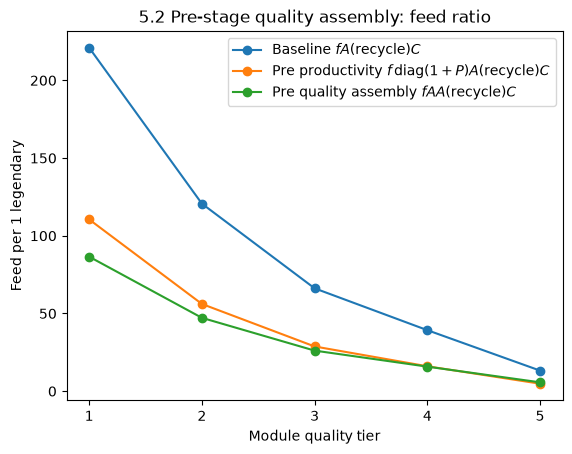

5 星建筑主循环: 全品质插件（产能禁用, P=50% 仅机器内部）
基线 fA(循环)C                 : 传奇产出 = 3.32226% | 进料比 = 30.1 : 1 | 与闭式之差 = 1.7e-13
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 9.13623% | 进料比 = 10.9454 : 1 | 与闭式之差 = 4.6e-13
前置建筑 f diag(1+50%)A(循环)C  : 传奇产出 = 4.9834% | 进料比 = 20.0666 : 1 | 与闭式之差 = 2.5e-13
前置品质组装 fAA(循环)C         : 传奇产出 = 8.49678% | 进料比 = 11.7692 : 1 | 与闭式之差 = 1.9e-13


In [8]:
import matplotlib.pyplot as plt

# 原材料品质组装 vs 纯产能前置：主循环取 4.3 的最优配比，在其上增加前置组装
tiers = list(range(1, 6))
y_base, y_prod, y_qual = [], [], []
for q_t in tiers:
    # 4.3 最优配比：枚举 p_n 取传奇产出最大者（4.4 闭式 M 算子）
    best_y, best_p_n = max(
        (
            float(
                (f @ loop_operator("电磁工厂", q_n=5 - p_n, q_t=q_t, p_n=p_n, p_t=q_t) @ L)
            ),
            p_n,
        )
        for p_n in range(6)
    )
    p_n, q_n = best_p_n, 5 - best_p_n
    M = loop_operator("电磁工厂", q_n=q_n, q_t=q_t, p_n=p_n, p_t=q_t)  # 主循环：4.3 最优配比
    A_q = electromagnetic_plant(q_n=5, q_t=q_t, p_n=0, p_t=0)  # 前置品质组装：5个品质插件，内部产能 50%
    # 纯产能前置 = 同一台前置机改为 5 个产能插件：内部产能 50% + 5 x 单件产能
    P_q = MACHINES["电磁工厂"]["base_productivity"] + 5 * PRODUCTIVITY_MOD3[q_t]

    P_main = MACHINES["电磁工厂"]["base_productivity"] + p_n * PRODUCTIVITY_MOD3[q_t]
    print(f"{q_t} 星 CPU 主循环最优: 产能x{p_n} 品质x{q_n}（q={q_n * QUALITY_MOD3[q_t]:.1%}, P={P_main:.0%}）")
    for label, head, bucket in (
        ("基线 fA(循环)C                 ", np.eye(5), y_base),
        ("前置纯产能 f diag(1+P)A(循环)C  ", diag([1 + P_q] * 5), y_prod),
        ("前置品质组装 fAA(循环)C         ", A_q, y_qual),
    ):
        y_leg = float((f @ head @ M @ L))
        # 与 4.4 之前的逐轮实现对比（同一调整后 A 口径）
        y_iter, _ = legendary_yield(
            electromagnetic_plant(q_n=q_n, q_t=q_t, p_n=p_n, p_t=q_t),
            recycler(q_t=q_t),
            head=head,
        )
        bucket.append(1 / y_leg)
        print(
            f"{label}: 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1"
            f" | 与闭式之差 = {abs(y_leg - y_iter):.1e}"
        )
    print()

# 折线图：进料比（进料/传奇产出）vs 插件品质星级
plt.figure()
plt.plot(tiers, y_base, marker="o", label=r"Baseline $fA(\mathrm{recycle})C$")
plt.plot(tiers, y_prod, marker="o", label=r"Pre productivity $f\,\mathrm{diag}(1+P)A(\mathrm{recycle})C$")
plt.plot(tiers, y_qual, marker="o", label=r"Pre quality assembly $fAA(\mathrm{recycle})C$")
plt.xticks(tiers)
plt.xlabel("Module quality tier")
plt.ylabel("Feed per 1 legendary")
plt.title("5.2 Pre-stage quality assembly: feed ratio")
plt.legend()
plt.show()

# 5星直接做建筑：产能插件禁用（节能插件无加成），矩阵无额外 P，只剩机器内部产能 50%
q_t = 5
M_b = loop_operator("电磁工厂", q_n=5, q_t=q_t, p_n=0, p_t=0)  # 全品质（节能无数学效果）
R = recycler(q_t=q_t)
A_q = electromagnetic_plant(q_n=5, q_t=q_t, p_n=0, p_t=0)  # 前置做中间品不受建筑限制
# 前置也是建筑：产能插件禁用，只剩机器内部产能 50%
P_q = MACHINES["电磁工厂"]["base_productivity"] + 5 * PRODUCTIVITY_MOD3[q_t]

print(f"5 星建筑主循环: 全品质插件（产能禁用, P={MACHINES['电磁工厂']['base_productivity']:.0%} 仅机器内部）")
for label, head in (
    ("基线 fA(循环)C                 ", np.eye(5)),
    ("前置纯产能 f diag(1+P)A(循环)C  ", diag([1 + P_q] * 5)),
    ("前置建筑 f diag(1+50%)A(循环)C  ", diag([1 + MACHINES["电磁工厂"]["base_productivity"]] * 5)),
    ("前置品质组装 fAA(循环)C         ", A_q),
):
    y_leg = float((f @ head @ M_b @ L))
    y_iter, _ = legendary_yield(
        electromagnetic_plant(q_n=5, q_t=q_t, p_n=0, p_t=0), R, head=head
    )
    print(
        f"{label}: 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1"
        f" | 与闭式之差 = {abs(y_leg - y_iter):.1e}"
    )

### 5.3 插件星级二维表：最优配比与进料比

对每种工厂，横纵坐标分别为品质与产能插件的星级（1~5）。每格枚举该机器插槽内品质/产能插件个数的分配（总数固定 = 插槽数），直接用闭式计算传奇进料比，给出最优个数组合与进料比。
回收机固定 4 个品质插件，星级取该行（品质）插件的星级。

In [9]:
# 二维表：行 = 品质插件星级，列 = 产能插件星级
# 格内容 = 最优(品质个数x/产能个数x) | 闭式进料比（4.4 M 算子）


for name in MACHINES:
    slots = MACHINES[name]["slots"]
    print(f"{name}（{slots} 槽）: 格式 = 品质x/产能x | 进料比")
    print("品质\\产能".ljust(10) + "".join(f"{t} 星".rjust(16) for t in range(1, 6)))
    for q_t in range(1, 6):
        row = f"{q_t} 星".ljust(10)
        for p_t in range(1, 6):
            best_y, best_q_n = max(
                (
                    float(
                        (
                            f
                            @ loop_operator(name, q_n=q_n, q_t=q_t, p_n=slots - q_n, p_t=p_t)
                         @ L)
                    ),
                    q_n,
                )
                for q_n in range(slots + 1)
            )
            cell = f"{best_q_n}Q/{slots - best_q_n}P {1 / best_y:.6g}"
            row += cell.rjust(16)
        print(row)
    print()

组装机3（4 槽）: 格式 = 品质x/产能x | 进料比
品质\产能                  1 星             2 星             3 星             4 星             5 星
1 星          4Q/0P 1072.63   4Q/0P 1036.92   3Q/1P 973.088   3Q/1P 879.418    2Q/2P 645.84
2 星            4Q/0P 626.6   4Q/0P 605.487   3Q/1P 567.082   3Q/1P 511.038   2Q/2P 371.841
3 星          4Q/0P 378.451   4Q/0P 365.613   3Q/1P 341.988   3Q/1P 307.611   2Q/2P 222.524
4 星          4Q/0P 260.818   4Q/0P 251.946   3Q/1P 235.529   3Q/1P 211.669   2Q/2P 152.752
5 星          4Q/0P 136.524   4Q/0P 131.871   3Q/1P 123.241    3Q/1P 110.71   2Q/2P 79.8786

电磁工厂（5 槽）: 格式 = 品质x/产能x | 进料比
品质\产能                  1 星             2 星             3 星             4 星             5 星
1 星          5Q/0P 221.002   5Q/0P 214.519   4Q/1P 198.442   3Q/2P 170.865   1Q/4P 103.914
2 星          5Q/0P 124.319   5Q/0P 120.658   4Q/1P 111.544   3Q/2P 95.9397   1Q/4P 58.3139
3 星          5Q/0P 73.7469   5Q/0P 71.5718   4Q/1P 66.1762   3Q/2P 56.9583   1Q/4P 34.8114
4 星          5Q/0P 50.7123   

### 5.4 两种工艺对比：先产能后品质 vs 先品质后产能

以 4 插槽、50% 基础产能的机器（铸造厂）做非中间产品为例。只讨论品质与产能插件全 1 星、全 3 星、全 5 星三种情况。注意非中间产物的机器不能放产能插件（游戏限制），两个 A 矩阵因此不同：

- 情况1：原料 →（只放产能插件）→ 原料 →（品质化，A 只放品质插件，无产能插件）→ 非中间产品，闭式 `f diag(1+P) A(循环) C`，其中 `P = 50%基础 + 4×插件产能`
- 情况2：原料 →（品质化，A 做中间产物，可按 4.3 最优比例配比）→ 5 星原料 →（只做 5 星产品，非中间产物不能放产能插件）→ 闭式 `f A(循环) C × (1+50%基础)`

回收机固定 4 个品质插件，星级同算例。

In [10]:
# 5.4：4 槽 50% 基础产能（铸造厂）做非中间产品：情况1 vs 情况2（4.4 M 算子）
name = "铸造厂"
slots = MACHINES[name]["slots"]
base_P = MACHINES[name]["base_productivity"]

for t in (1, 3, 5):
    # 情况1：前置做材料，全产能插件 P = 50%基础 + 4x插件；A 做非中间产物只放品质
    P1 = base_P + slots * PRODUCTIVITY_MOD3[t]
    head = diag([1 + P1] * 5)
    M1 = loop_operator(name, q_n=slots, q_t=t, p_n=0, p_t=0)  # 4 品质；非中间产物禁产能插件 -> p_t=0
    y1 = float((f @ head @ M1 @ L))

    # 情况2：A 做中间产物按 4.3 最优比例；尾部做非中间产物无产能插件，只有基础产能
    best_y2, best_p_n = max(
        (
            float(
                (
                    f
                    @ loop_operator(name, q_n=slots - p_n, q_t=t, p_n=p_n, p_t=t)
                 @ L)
            ),
            p_n,
        )
        for p_n in range(slots + 1)
    )
    y2 = (1 + base_P) * best_y2

    print(f"{t} 星插件:")
    print(
        f"情况1 f(1+P)A(循环)C: 4Q/0P | 传奇产出 = {y1 * 100:.6g}%"
        f" | 进料比 = {1 / y1:.6g} : 1"
    )
    print(
        f"情况2 fA(循环)C(1+50%): {slots - best_p_n}Q/{best_p_n}P | 传奇产出 = {y2 * 100:.6g}%"
        f" | 进料比 = {1 / y2:.6g} : 1"
    )
    print()

1 星插件:
情况1 f(1+P)A(循环)C: 4Q/0P | 传奇产出 = 0.566956% | 进料比 = 176.38 : 1
情况2 fA(循环)C(1+50%): 4Q/0P | 传奇产出 = 0.492536% | 进料比 = 203.031 : 1

3 星插件:
情况1 f(1+P)A(循环)C: 4Q/0P | 传奇产出 = 1.90431% | 进料比 = 52.5124 : 1
情况2 fA(循环)C(1+50%): 4Q/0P | 传奇产出 = 1.55082% | 进料比 = 64.4821 : 1

5 星插件:
情况1 f(1+P)A(循环)C: 4Q/0P | 传奇产出 = 6.13123% | 进料比 = 16.31 : 1
情况2 fA(循环)C(1+50%): 1Q/3P | 传奇产出 = 6.18043% | 进料比 = 16.1801 : 1



### 5.5 混合品质与产能（按输入品质分档配置）

前面所有模拟都假设 1~4 星输入用同一套插件配比，只有 5 星输入因品质插件失效而固定全产能。但数学直觉提示：低星输入时品质插件的边际收益更高，可能总是值得多插几个品质插件，甚至全品质；高星输入则相反。也就是说，逐档配置可能优于统一配比。

这在代数上只是把组装矩阵 $A$ 从 $\mathrm{diag}(1+P)\,Q(q)$ 改为**按输入品质分档**：输入为第 $i$ 品质时用该档自己的插件配比 $(q_i, P_i)$，即 $A_{i,:} = (1+P_i)\,Q(q_i)_{i,:}$。其它代数式完全不变，$M$ 仍是第 3 章的公式：

$$M = A\,(I - SRA)^{-1}\,C,\quad \mathbf y = fM$$

下面封装成函数：只传入设备、产能插件星级（0~5，0=该设备禁产能插件）、品质插件星级（1~5），内部按输入品质分档枚举——5 星输入固定全产能（品质插件无效），1~4 星输入各从 6 种配比（0~5 个品质插件）中选，共 $6^4$ 种组合，取传奇产出最大者，并与同配比方案对照。

枚举结果几乎总是同配比，这不是巧合：$Q$ 的上三角转移概率只依赖跳跃步长（平移不变），使整个闭环近似尺度不变，价值向量 $v_i$（从第 $i$ 品质出发的传奇期望）近似几何增长——比值 $v_{i+1}/v_i$ 逐档几乎相同（电磁工厂 1Q/4P @5 星时约为 2.36）。既然每一档"多一次品质升级"的边际价值比例相同，最优配比也就逐档相同。唯一的例外来源是通往传奇的最后一步：$Q$ 的传奇列缺少 0.9 因子（会溢出到更高级的滚动被截断在传奇），且传奇输入行由 5->5 调整锁死为纯产能，使 $v_4/v_3$ 偏离（约 2.77）。这个偏离积累起来才会产生分档红利，且都很小：铸造厂（4 槽）5 星插件时 (1,1,1,2) 提升约 0.1%，低温工厂（8 槽）1 星产能时 (6,6,6,7) 提升约 0.1%。下面对多组设备/星级枚举，并打印价值向量比值验证。

In [11]:
# 5.5 混合配置：按输入品质分档选配比；只传设备、产能插件星级、品质插件星级
def mixed_best(name, p_t, q_t):
    """分档枚举最优配比：第 i 品质输入从 0~插槽数 个 q_t 星品质插件中选（其余为
    p_t 星产能插件），5 星输入固定全产能；打印最优分档与同配比对照，
    返回 (最优进料比, 最优配置)。"""
    spec = MACHINES[name]
    slots = spec["slots"]
    base_P = spec["base_productivity"]
    q_mod = QUALITY_MOD3[q_t]
    p_mod = PRODUCTIVITY_MOD3[p_t]
    R = recycler(q_t=q_t)

    def y_of(configs):
        A = np.zeros((5, 5))
        for i in range(5):
            q_n = configs[i]
            P = base_P + (slots - q_n) * p_mod
            A[i, :] = (1 + P) * Q(q_n * q_mod)[i, :]
        return float((f @ A @ np.linalg.inv(np.eye(5) - S @ R @ A) @ L))

    # 5 星输入固定全产能（品质插件 0 个），枚举 1~4 星输入配比：6^4 种
    best = (-1.0, None)
    uniform = {}
    for c1 in range(slots + 1):
        for c2 in range(slots + 1):
            for c3 in range(slots + 1):
                for c4 in range(slots + 1):
                    y = y_of((c1, c2, c3, c4, 0))
                    if y > best[0]:
                        best = (y, (c1, c2, c3, c4, 0))
                    if c1 == c2 == c3 == c4:
                        uniform[c1] = y

    y_star, cfg = best
    labels = ["1 星", "2 星", "3 星", "4 星", "5 星"]
    print(f"{name}（品质插件 {q_t} 星 + 产能插件 {p_t} 星）最优分档（品质/产能插件数）:")
    print("  " + " | ".join(f"{labels[i]}输入 {cfg[i]}Q/{slots - cfg[i]}P" for i in range(5)))
    print(f"  传奇产出 = {y_star * 100:.6g}% | 进料比 = {1 / y_star:.6g} : 1")

    best_k = max(uniform, key=uniform.get)
    y_uni = uniform[best_k]
    print(
        f"最优同配比 k={best_k}: 传奇产出 = {y_uni * 100:.6g}% | 进料比 = {1 / y_uni:.6g} : 1"
    )
    print(f"分档相对最优同配比提升: {(y_star / y_uni - 1) * 100:.4g}%")
    return 1 / y_star, cfg


# 示例 1：全部设备，品质/产能插件均 5 星（电炉实际禁产能插件，此处仅作模型对照）
for name in MACHINES:
    mixed_best(name, p_t=5, q_t=5)
    print()

# 示例 2：其它星级组合，观察分档是否偏离同配比
for name, p_t, q_t in (
    ("电磁工厂", 1, 5),
    ("电磁工厂", 3, 3),
    ("电磁工厂", 1, 1),
    ("低温工厂", 1, 5),
):
    mixed_best(name, p_t=p_t, q_t=q_t)
    print()

# 价值向量诊断：v[i] = 从第 i 品质出发（先过组装再循环）的传奇期望
# 比值逐档近似常数 => 各档最优配比相同；只有通往传奇的最后一步偏离
name, p_t, q_t = "电磁工厂", 5, 5
spec = MACHINES[name]
slots, base_P = spec["slots"], spec["base_productivity"]
A = np.zeros((5, 5))
for i in range(5):
    q_n = 0 if i == 4 else 1  # 1Q/4P 同配比
    P = base_P + (slots - q_n) * PRODUCTIVITY_MOD3[p_t]
    A[i, :] = (1 + P) * Q(q_n * QUALITY_MOD3[q_t])[i, :]
V = A @ np.linalg.inv(np.eye(5) - S @ recycler(q_t=q_t) @ A)
v = V[:, 4]
print("价值向量 v（电磁工厂 1Q/4P @5 星）:", v)
print("比值 v[i+1]/v[i] =", v[1:] / v[:-1])

组装机3（品质插件 5 星 + 产能插件 5 星）最优分档（品质/产能插件数）:
  1 星输入 2Q/2P | 2 星输入 2Q/2P | 3 星输入 2Q/2P | 4 星输入 2Q/2P | 5 星输入 0Q/4P
  传奇产出 = 1.2519% | 进料比 = 79.8786 : 1
最优同配比 k=2: 传奇产出 = 1.2519% | 进料比 = 79.8786 : 1
分档相对最优同配比提升: 0%



电磁工厂（品质插件 5 星 + 产能插件 5 星）最优分档（品质/产能插件数）:
  1 星输入 1Q/4P | 2 星输入 1Q/4P | 3 星输入 1Q/4P | 4 星输入 1Q/4P | 5 星输入 0Q/5P
  传奇产出 = 7.55635% | 进料比 = 13.2339 : 1
最优同配比 k=1: 传奇产出 = 7.55635% | 进料比 = 13.2339 : 1
分档相对最优同配比提升: 0%



铸造厂（品质插件 5 星 + 产能插件 5 星）最优分档（品质/产能插件数）:
  1 星输入 1Q/3P | 2 星输入 1Q/3P | 3 星输入 1Q/3P | 4 星输入 2Q/2P | 5 星输入 0Q/4P
  传奇产出 = 4.12432% | 进料比 = 24.2464 : 1
最优同配比 k=1: 传奇产出 = 4.12028% | 进料比 = 24.2702 : 1
分档相对最优同配比提升: 0.09791%

电炉（品质插件 5 星 + 产能插件 5 星）最优分档（品质/产能插件数）:
  1 星输入 2Q/0P | 2 星输入 2Q/0P | 3 星输入 2Q/0P | 4 星输入 2Q/0P | 5 星输入 0Q/2P
  传奇产出 = 0.324414% | 进料比 = 308.248 : 1
最优同配比 k=2: 传奇产出 = 0.324414% | 进料比 = 308.248 : 1
分档相对最优同配比提升: 0%

化工厂（品质插件 5 星 + 产能插件 5 星）最优分档（品质/产能插件数）:
  1 星输入 2Q/1P | 2 星输入 2Q/1P | 3 星输入 2Q/1P | 4 星输入 2Q/1P | 5 星输入 0Q/3P
  传奇产出 = 0.656637% | 进料比 = 152.291 : 1
最优同配比 k=2: 传奇产出 = 0.656637% | 进料比 = 152.291 : 1
分档相对最优同配比提升: 0%



低温工厂（品质插件 5 星 + 产能插件 5 星）最优分档（品质/产能插件数）:
  1 星输入 0Q/8P | 2 星输入 0Q/8P | 3 星输入 0Q/8P | 4 星输入 0Q/8P | 5 星输入 0Q/8P
  传奇产出 = 14.5056% | 进料比 = 6.89389 : 1
最优同配比 k=0: 传奇产出 = 14.5056% | 进料比 = 6.89389 : 1
分档相对最优同配比提升: 0%

电磁工厂（品质插件 5 星 + 产能插件 1 星）最优分档（品质/产能插件数）:
  1 星输入 5Q/0P | 2 星输入 5Q/0P | 3 星输入 5Q/0P | 4 星输入 5Q/0P | 5 星输入 0Q/5P
  传奇产出 = 3.69703% | 进料比 = 27.0488 : 1
最优同配比 k=5: 传奇产出 = 3.69703% | 进料比 = 27.0488 : 1
分档相对最优同配比提升: 0%



电磁工厂（品质插件 3 星 + 产能插件 3 星）最优分档（品质/产能插件数）:
  1 星输入 4Q/1P | 2 星输入 4Q/1P | 3 星输入 4Q/1P | 4 星输入 4Q/1P | 5 星输入 0Q/5P
  传奇产出 = 1.51112% | 进料比 = 66.1762 : 1
最优同配比 k=4: 传奇产出 = 1.51112% | 进料比 = 66.1762 : 1
分档相对最优同配比提升: 0%

电磁工厂（品质插件 1 星 + 产能插件 1 星）最优分档（品质/产能插件数）:
  1 星输入 5Q/0P | 2 星输入 5Q/0P | 3 星输入 5Q/0P | 4 星输入 5Q/0P | 5 星输入 0Q/5P
  传奇产出 = 0.452485% | 进料比 = 221.002 : 1
最优同配比 k=5: 传奇产出 = 0.452485% | 进料比 = 221.002 : 1
分档相对最优同配比提升: 0%



低温工厂（品质插件 5 星 + 产能插件 1 星）最优分档（品质/产能插件数）:
  1 星输入 6Q/2P | 2 星输入 6Q/2P | 3 星输入 6Q/2P | 4 星输入 7Q/1P | 5 星输入 0Q/8P
  传奇产出 = 2.35774% | 进料比 = 42.4134 : 1
最优同配比 k=6: 传奇产出 = 2.35511% | 进料比 = 42.4609 : 1
分档相对最优同配比提升: 0.1118%

价值向量 v（电磁工厂 1Q/4P @5 星）: [0.0756 0.1783 0.4205 0.9923 2.75  ]
比值 v[i+1]/v[i] = [2.359  2.3591 2.3596 2.7714]


### 5.6 其它产能来源

还有若干未展开的产能来源：例如塑料、CPU 等配方可以被科技（研究）加上产能加成。这类加成与设备基础产能同级，直接代入 $P$（$P$ = 基础产能 + 产能插件 + 科技加成）即可，对 $M = A\,(I - SRA)^{-1}\,C$ 等代数式没有结构性影响，本文不再展开。

### 5.7 各等级设备量如何计算

第 3 章只算了最终传奇产出率。要实际布线还需求出循环中每一级品质的累计流量，再换算成设备台数。沿用 3.2 的逐轮展开即可。

**组装机累计进料**。第一轮进料 $f$；每轮"组装→掩码→回收"把非传奇变成材料送回进料，所以各轮进组装机的材料依次是

$$
f,\quad fASR,\quad fASRASR,\quad \cdots
$$

累计进料（即全部轮次进组装机的流量之和）为

$$
f + fASR + fASRASR + \cdots \;=\; f\,(I - ASR)^{-1}.
$$

注意回收机也能把史诗升到传奇，故回流 $fASR$ 的传奇分量非零——它照样进组装机，再在下一轮被收集。

**回收机累计进料**与**传奇收集**同样逐轮累加：

$$
\begin{aligned}
\text{进回收机} &= fAS + fASRAS + \cdots \;=\; f\,(I-ASR)^{-1}AS,\\
\text{传奇收集} &= fAC + fASRAC + \cdots \;=\; fA\,(I-SRA)^{-1}C \quad(\text{即 3.3 的 } y).
\end{aligned}
$$

**设备台数**。设组装机单台件率 $\nu_A$（= 速度 / 单件制作时间）、回收机单台件率 $\nu_R$。回收耗时 = 制作时间 / 16，回收机基础速度 0.5，故两台速度同为 1 时 $\nu_R = 8\,\nu_A$。注意台数比依赖同一件物品的制作时间；组装与回收若不是同一件物品，要按各自配方时间分别换算，不能直接套件数比。目标传奇产率 $Y$ 时进料标量 $f_0 = Y/y$，把累计流量同乘 $f_0$ 再除以单台件率即得台数：

$$
N_A = \frac{f_0 \cdot \text{组装机累计进料之和}}{\nu_A},\qquad
N_R = \frac{f_0 \cdot \text{进回收机之和}}{\nu_R}.
$$

**逐档台数**。组装机累计进料的各品质分量给出皮带上每一级品质的通量；若按品质分道（5.5 的分档方案），逐档台数 $N_i = f_0\, m_i / \nu_A$。各档流量极不均衡：1 星档与 5 星档常相差约两个数量级（例中 $m_1 : m_5 \approx 200 : 1$）——"5 星组装"摊下来的量远不足一台机器，高星档只是回收机偶尔升出的料顺路过机，**不值得让任何一档满载**。

实际配机不需要逐档精确：只需要 1 份 5 星输出时，先按满带进料定下 1 星组装机数量（$f_0\,m_1/\nu_A$），其余各档按流量比例 $\lceil m_i/m_1 \rceil$ 向上取整即可——高星档各配 1 台富余量也极小。

In [12]:
# 5.7 示例：铸造厂(4槽) + 4x5星品质 + 禁产能，回收机 4x5星品质
q = 4 * QUALITY_MOD3[5]
A = 1.5 * Q(q)          # 基础产能 50%，无产能插件
R = 0.25 * Q(q)
# 闭式（同 md 中各级级数之和）
feed_cum = f @ np.linalg.inv(np.eye(5) - A @ S @ R)          # f + fASR + fASRASR + ...
rec_tot = float((feed_cum @ A @ S).sum())                    # 累计进回收机之和
y = float((feed_cum @ A @ L))                             # fAC + fASRAC + ...
print(f"组装机累计进料 f+fASR+...  = {feed_cum}  总={feed_cum.sum():.3f}")
print(f"累计进回收机之和 = {rec_tot:.3f}")
print(f"传奇收集 fAC+fASRAC+... = {y*100:.3f}% | 进料比 {1/y:.1f}:1")
# 对照 3.3 的闭式 fA(I-SRA)^-1C
y_closed = float((f @ A @ np.linalg.inv(np.eye(5) - S @ R @ A) @ L))
print(f"对照 y = fA(I-SRA)^-1C = {y_closed*100:.3f}%  (差 {abs(y-y_closed):.1e})")
# 逐档台数：目标传奇 1 件/秒，nu_A = 1 件/s
Y, nu_A = 1.0, 1.0
f0 = Y / y
N_i = f0 * feed_cum / nu_A
print(f"\n目标传奇 {Y:.0f} 件/s：进料 {f0:.1f} 件/s")
for i in range(5):
    print(f"  {i+1} 星档组装机流量 = {f0*feed_cum[i]:.3f} 件/s -> {N_i[i]:.2f} 台，相对1星 {feed_cum[i]/feed_cum[0]:.4f}")
N_up = [int(np.ceil(N_i[0] * feed_cum[i] / feed_cum[0])) for i in range(5)]
print(f"  按比例向上取整: {N_up} 台（以1星档 {N_i[0]:.2f} 台为基准）")
print(f"  组装机总件率 {f0*feed_cum.sum():.1f} 件/s -> N_A = {f0*feed_cum.sum()/nu_A:.0f} 台")
print(f"  回收机总件率 {f0*rec_tot:.1f} 件/s -> N_R = {f0*rec_tot/(8*nu_A):.1f} 台 (nu_R=8*nu_A)")
print(f"  台数比 N_R : N_A = {rec_tot/(8*feed_cum.sum()):.3f}，即 1 台回收对 {8*feed_cum.sum()/rec_tot:.1f} 台组装")

组装机累计进料 f+fASR+...  = [1.2691 0.2028 0.0828 0.0293 0.0062]  总=1.590
累计进回收机之和 = 2.361
传奇收集 fAC+fASRAC+... = 2.452% | 进料比 40.8:1
对照 y = fA(I-SRA)^-1C = 2.452%  (差 6.9e-18)

目标传奇 1 件/s：进料 40.8 件/s
  1 星档组装机流量 = 51.749 件/s -> 51.75 台，相对1星 1.0000
  2 星档组装机流量 = 8.268 件/s -> 8.27 台，相对1星 0.1598
  3 星档组装机流量 = 3.375 件/s -> 3.37 台，相对1星 0.0652
  4 星档组装机流量 = 1.195 件/s -> 1.20 台，相对1星 0.0231
  5 星档组装机流量 = 0.253 件/s -> 0.25 台，相对1星 0.0049
  按比例向上取整: [52, 9, 4, 2, 1] 台（以1星档 51.75 台为基准）
  组装机总件率 64.8 件/s -> N_A = 65 台
  回收机总件率 96.3 件/s -> N_R = 12.0 台 (nu_R=8*nu_A)
  台数比 N_R : N_A = 0.186，即 1 台回收对 5.4 台组装


### 5.8 只能自回收的材料：组装其它产品再拆解会更好吗？

钢、碳化钨这类冶炼/化学产物只能自回收（25% 概率返回自身），开不了 A+R 环。若下游需要它的传奇版本，除了直接堆品质插件逐级制作（上一节讨论过），还有一个候选：**把它组装成别的产品再拆解**——组装侧用高产能插件堆量，回收机的品质滚动作用在拆解回流的材料上，收集传奇材料。

记材料进料 $f$、组装矩阵 $A = \mathrm{diag}(1+P)\,Q(q)$、回收矩阵 $R$（固定 4 个品质插件）。两个方案的用料比例：

**方案 1：组装成目标产品，收集传奇产品**（即第 3 章的 A+R 环）：

$$
y_1 \;=\; fAC + fASRAC + \cdots \;=\; fA\,(I - SRA)^{-1}\,L .
$$

**方案 2：组装成任意可拆解的中间产品，收集传奇材料**——品质滚动发生在回收拆解那一步（回收机固定 4 品质插件），组装侧只负责产能：

$$
y_2^{\text{料}} \;=\; fARC + fARSARC + \cdots \;=\; fAR\,(I - SAR)^{-1}\,L .
$$

$y_2^{\text{料}}$ 是"每份材料出多少传奇**材料**"。要与 $y_1$ 对比"每传奇产品"口径，还需最后一步制作：传奇材料直接做出传奇产品（输入已传奇，无需品质插件），且吃满该步产能，故

$$
y_2 \;=\; (1 + P_{\text{终}})\; y_2^{\text{料}} ,
$$

$P_{\text{终}}$ 为最终制作的总产能倍率。注意 $y_2$ 的含义随口径变化：$y_2^{\text{料}}$ 按材料计，$y_2$ 按产品计；与 $y_1$ 比较务必用同一口径。

**方法即以上三式**：代入具体设备、插件档位与收集点即可。以下以碳化钨为例演示一遍流程，不穷举所有情况。方案 2 的组装设备分三种情形，**表达式完全相同**，只是 $A$ 的取法不同：

- **情形 a：设备/配方禁产能插件**（如低温工厂生产非中间产品）——插槽全给品质，$A$ 唯一；
- **情形 b：可用产能插件、换设备**（如低温工厂生产中间产品）——$A$ 随品质/产能分配变化，枚举求最优；
- **情形 c：不换设备、只换配方**（同一设备生产另一种可插产能的中间产品）——设备的基础产能与插槽数不变，仅配方从"禁产能"变为"可产能"，同样枚举求最优。

In [13]:
# 5.8 示例：碳化钨(只能自回收)，回收机 4x5星
q5, p5 = QUALITY_MOD3[5], PRODUCTIVITY_MOD3[5]
P_final = 0.5  # 最终制作：铸造厂基础产能 50%（传奇输入->传奇输出，无需品质插件）
R = 0.25 * Q(4 * q5)
# 纯自回收对照（25% 概率返回自身）
y_pure = float((f @ R @ np.linalg.inv(np.eye(5) - S @ R) @ L))
print(f"纯R自回收:        {y_pure*100:.5f}% | {1/y_pure:.1f} 份/传奇")
# 方案1：铸造厂生产铸造厂(非中间产品, 无额外产能插件)，收集传奇产品
A_1 = 1.5 * Q(4 * q5)
y_1 = float((f @ A_1 @ np.linalg.inv(np.eye(5) - S @ R @ A_1) @ L))
print(f"方案1 铸造厂生产铸造厂: {y_1*100:.4f}% | {1/y_1:.1f} 份材料/传奇产品")
# 方案2：拆解收集传奇材料，再 x(1+P_final) 折算到产品口径
# 情形a：低温工厂生产非中间产品(禁产能插件) -> 8槽全品质，配置唯一
A_2a = 1.0 * Q(8 * q5)
y_2a_mat = float((f @ A_2a @ R @ np.linalg.inv(np.eye(5) - S @ A_2a @ R) @ L))
y_2a = (1 + P_final) * y_2a_mat
print(f"方案2a 低温工厂全品质(8Q): {y_2a*100:.4f}% | 料 {1/y_2a_mat:.1f} | 产品 {1/y_2a:.1f} 份材料/传奇产品")
# 情形b：低温工厂生产中间产品(可用产能插件)，枚举8槽分配求最优
print("方案2b 低温工厂可用产能插件:")
best_b = None
for qn in range(9):
    pn = 8 - qn
    A_2b = (1 + pn * p5) * Q(qn * q5)
    y_2b = (1 + P_final) * float((f @ A_2b @ R @ np.linalg.inv(np.eye(5) - S @ A_2b @ R) @ L))
    if best_b is None or y_2b > best_b[0]:
        best_b = (y_2b, qn, pn)
    print(f"  {qn}Q+{pn}P: {y_2b*100:.4f}% | 产品 {1/y_2b:.1f} 份材料/传奇产品")
print(f"方案2b 最优: {best_b[1]}Q+{best_b[2]}P -> {1/best_b[0]:.1f} 份材料/传奇产品")
# 情形c：不换设备(仍用铸造厂)，只换配方为可插产能的中间产品，枚举4槽分配
print("方案2c 铸造厂换可产能配方:")
best_c = None
for qn in range(5):
    pn = 4 - qn
    A_2c = (1 + 0.5 + pn * p5) * Q(qn * q5)  # 基础产能 50% + 产能插件
    y_2c = (1 + P_final) * float((f @ A_2c @ R @ np.linalg.inv(np.eye(5) - S @ A_2c @ R) @ L))
    if best_c is None or y_2c > best_c[0]:
        best_c = (y_2c, qn, pn)
    print(f"  {qn}Q+{pn}P: {y_2c*100:.4f}% | 产品 {1/y_2c:.1f} 份材料/传奇产品")
print(f"方案2c 最优: {best_c[1]}Q+{best_c[2]}P -> {1/best_c[0]:.1f} 份材料/传奇产品")

纯R自回收:        0.03667% | 2726.9 份/传奇
方案1 铸造厂生产铸造厂: 2.4525% | 40.8 份材料/传奇产品
方案2a 低温工厂全品质(8Q): 1.1802% | 料 127.1 | 产品 84.7 份材料/传奇产品
方案2b 低温工厂可用产能插件:
  0Q+8P: 7.2528% | 产品 13.8 份材料/传奇产品
  1Q+7P: 6.5434% | 产品 15.3 份材料/传奇产品
  2Q+6P: 5.7168% | 产品 17.5 份材料/传奇产品
  3Q+5P: 4.8551% | 产品 20.6 份材料/传奇产品
  4Q+4P: 4.0029% | 产品 25.0 份材料/传奇产品
  5Q+3P: 3.1893% | 产品 31.4 份材料/传奇产品
  6Q+2P: 2.4362% | 产品 41.0 份材料/传奇产品
  7Q+1P: 1.7614% | 产品 56.8 份材料/传奇产品
  8Q+0P: 1.1802% | 产品 84.7 份材料/传奇产品
方案2b 最优: 0Q+8P -> 13.8 份材料/传奇产品
方案2c 铸造厂换可产能配方:
  0Q+4P: 2.1019% | 产品 47.6 份材料/传奇产品
  1Q+3P: 2.2312% | 产品 44.8 份材料/传奇产品
  2Q+2P: 2.1050% | 产品 47.5 份材料/传奇产品
  3Q+1P: 1.8381% | 产品 54.4 份材料/传奇产品
  4Q+0P: 1.5018% | 产品 66.6 份材料/传奇产品
方案2c 最优: 1Q+3P -> 44.8 份材料/传奇产品


## 6 外部工具

- [Factorio Quality 计算器](https://cromarmot.github.io/Debuq/#/tools/factorio/quality)（Debuq 工具集）——内容待补充。